In [1]:
#Data Manipulation specific
import numpy as np
import pandas as pd
import xarray as xr

from netCDF4 import Dataset

import matplotlib.pyplot as plt
from mpl_toolkits.basemap import Basemap

import cartopy.crs as ccrs
import cartopy.feature as cfeature

/home/anas.oubaha/.local/lib/python3.8/site-packages/pandas/core/computation/expressions.py:20: UserWarning: Pandas requires version '2.7.3' or newer of 'numexpr' (version '2.7.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


ModuleNotFoundError: No module named 'cartopy'

In [ ]:
%pip install C:/Users/Oubaha.ANAS/GDAL-3.4.3-cp39-cp39-win_amd64.whl

In [2]:
!pip install cartopy

Defaulting to user installation because normal site-packages is not writeable
  Using cached Cartopy-0.21.1.tar.gz (10.9 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
    Preparing wheel metadata ... done
  Using cached shapely-2.0.7-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (2.5 MB)
  ERROR: Command errored out with exit status 1:
   command: /srv/software/easybuild/software/Anaconda3/2020.11/bin/python /srv/software/easybuild/software/Anaconda3/2020.11/lib/python3.8/site-packages/pip/_vendor/pep517/_in_process.py build_wheel /tmp/tmp5tqu5pg9
       cwd: /tmp/pip-install-uj7er1rl/cartopy
  Complete output (288 lines):
  <string>:90: UserWarning: Unable to determine GEOS version. Ensure you have 3.7.2 or later installed, or installation may fail.
  /tmp/pip-build-env-qoeqyurd/overlay/lib/python3.8/site-packages/setuptools/_distutils/dist.py:261: UserWarning: Unknown distribution option: 'tests_require'
    warnings.warn(msg)


In [2]:
!free -g

              total        used        free      shared  buff/cache   available
Mem:            376          96         215           6          64         269
Swap:             0           0           0


**Read NC data and calculate sst monthly anomalies**

In [3]:
#xarry bach n7ol les fichier
#sst= xr.open_dataset('C:/Users/Oubaha.ANAS/Workspace/Datasets/HadISST/HadISST_sst.nc')
dsst= xr.open_dataset('data/sst.nc', engine='netcdf4')
dsst['sst'].assign_coords(date=pd.to_datetime(dsst['sst'].date.values))

FileNotFoundError: [Errno 2] No such file or directory: '/home/anas.oubaha/ondemand/data/sys/dashboard/batch_connect/sys/bc_desktop/slurm/data/sst.nc'

In [ ]:
# Load dataset (Uncomment if loading from file)

sst = dsst['sst']  # Replace 'sst' with the actual variable name

# Ensure 'date' is properly formatted as pandas datetime
sst = sst.assign_coords(date=pd.to_datetime(sst.date.values))

# Convert to pandas DataFrame
df = sst.to_dataframe().reset_index()

# Extract month from date
df['month'] = df['date'].dt.month

# Compute long-term monthly climatology
# Filter to only include seasons from 1991 to 2020 (30 years period recommended by the WMO)
filtered_df = seasonal_vimdf_df[(seasonal_vimdf_df['season_year'] >= 1991) & (seasonal_vimdf_df['season_year'] <= 2020)]
climatology = df.groupby(['latitude', 'longitude', 'month'])['sst'].mean().reset_index()

# Merge to compute anomalies
df = df.merge(climatology, on=['latitude', 'longitude', 'month'], suffixes=('', '_climatology'))
df['sst_anomaly'] = df['sst'] - df['sst_climatology']

# Convert back to xarray
anomalies = df.set_index(['date', 'latitude', 'longitude'])['sst_anomaly'].to_xarray()


In [12]:
unique_dates = pd.date_range(start="1983-01", periods=anomalies.sizes["date"], freq="MS")
anomalies = anomalies.assign_coords(date=("date", unique_dates))
anomalies

<xarray.DataArray 'sst_anomaly' (date: 492, latitude: 721, longitude: 1440)>
array([[[           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        ...,
        [ 1.2207031e-04,  1.2207031e-04,  1.2207031e-04, ...,
          1.2207031e-04,  1.2207031e-04,  1.2207031e-04],
        [ 1.2207031e-04,  1.8310547e-04,  1.5258789e-04, ...,
          1.2207031e-04,  1.2207031e-04,  1.2207031e-04],
        [ 1.2207031e-04,  1.2207031e-04,  1.2207031e-04, ...,
          1.2207031e-04,  1.2207031e-04,  1.2207031e-04]],

       [[           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
...
        [ 3.6621094e-04,  3.6621094e-04,  3.6621094e-04, ...,
          3.6621094e-04,  3.6621094e-04,  3.6621094e-04],
        [ 3.6621094e-04,  4.2724609e-04,  3.9672852e-04, ...,
          3.6621094e-04,  3.6621094e-04,  3.6621094e-04],
        [ 3.6621094e-04,  3.6621094e-04,  3.6621094e-04, ...,
          3.6621094e-04,  3.6621094e-04,  3.6621094e-04]],

       [[           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        ...,
        [ 1.2207031e-04,  1.2207031e-04,  1.2207031e-04, ...,
          1.2207031e-04,  1.2207031e-04,  1.2207031e-04],
        [ 1.2207031e-04,  1.8310547e-04,  1.5258789e-04, ...,
          1.2207031e-04,  1.2207031e-04,  1.2207031e-04],
        [ 1.2207031e-04,  1.2207031e-04,  1.2207031e-04, ...,
          1.2207031e-04,  1.2207031e-04,  1.2207031e-04]]], dtype=float32)
Coordinates:
  * date       (date) datetime64[ns] 1983-01-01 1983-02-01 ... 2023-12-01
  * latitude   (latitude) float64 -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * longitude  (longitude) float64 0.0 0.25 0.5 0.75 ... 359.0 359.2 359.5 359.8

In [38]:
# Save SST anomalies dataset as a NetCDF file
anomalies.to_netcdf("sst_anomalies.nc")

**Plotting sst anomalies for a target month**

In [4]:
anomalies= xr.open_dataset('data/sst_anomalies.nc', engine='netcdf4')
anomalies

<xarray.Dataset>
Dimensions:      (date: 492, latitude: 721, longitude: 1440)
Coordinates:
  * date         (date) datetime64[ns] 1983-01-01 1983-02-01 ... 2023-12-01
  * latitude     (latitude) float64 -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * longitude    (longitude) float64 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
Data variables:
    sst_anomaly  (date, latitude, longitude) float32 ...

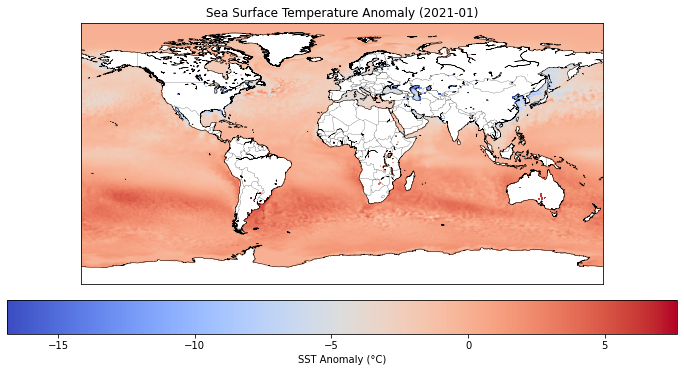

In [4]:
# Select a specific month and year for visualization (e.g., January 2020)
target_date = "2021-01-01"
sst_anomaly = anomalies.sel(date=target_date, method="nearest").to_array().squeeze()
sst_anomaly = sst_anomaly.assign_coords(longitude=(((sst_anomaly.longitude + 180) % 360) - 180)).sortby("longitude")

# Plot anomaly map
fig, ax = plt.subplots(figsize=(12, 6))

# Create Basemap centered around Africa
m = Basemap(projection="cyl", resolution="l", ax=ax,
            llcrnrlon=-180, urcrnrlon=180,  # Full longitude range
            llcrnrlat=-90, urcrnrlat=90)  # Focused latitude range

# Convert lat/lon to Basemap coordinates
lon, lat = np.meshgrid(sst_anomaly.longitude, sst_anomaly.latitude)
x, y = m(lon, lat)

# Plot the SST anomaly data
pcm = m.pcolormesh(x, y, sst_anomaly, cmap="coolwarm", shading="auto")

# Add coastlines and countries
m.drawcoastlines(linewidth=0.5)
m.drawcountries(linewidth=0.2)

# Add colorbar
cbar = plt.colorbar(pcm, ax=ax, orientation="horizontal", pad=0.05)
cbar.set_label("SST Anomaly (°C)")

# Add title
plt.title(f"Sea Surface Temperature Anomaly ({target_date[:-3]})")

# Show the plot
plt.show()

In [44]:
fig.savefig(f"SSTAnomaly{target_date[:-3]}.png", dpi=1200, bbox_inches="tight", format="png")

**Plotting sst anomalies for a period**

<ipython-input-11-fe62e28f1ce3>:21: UserWarning: This figure was using constrained_layout==True, but that is incompatible with subplots_adjust and or tight_layout: setting constrained_layout==False. 
  fig.subplots_adjust(bottom=0.12)  # Adjust space for colorbar


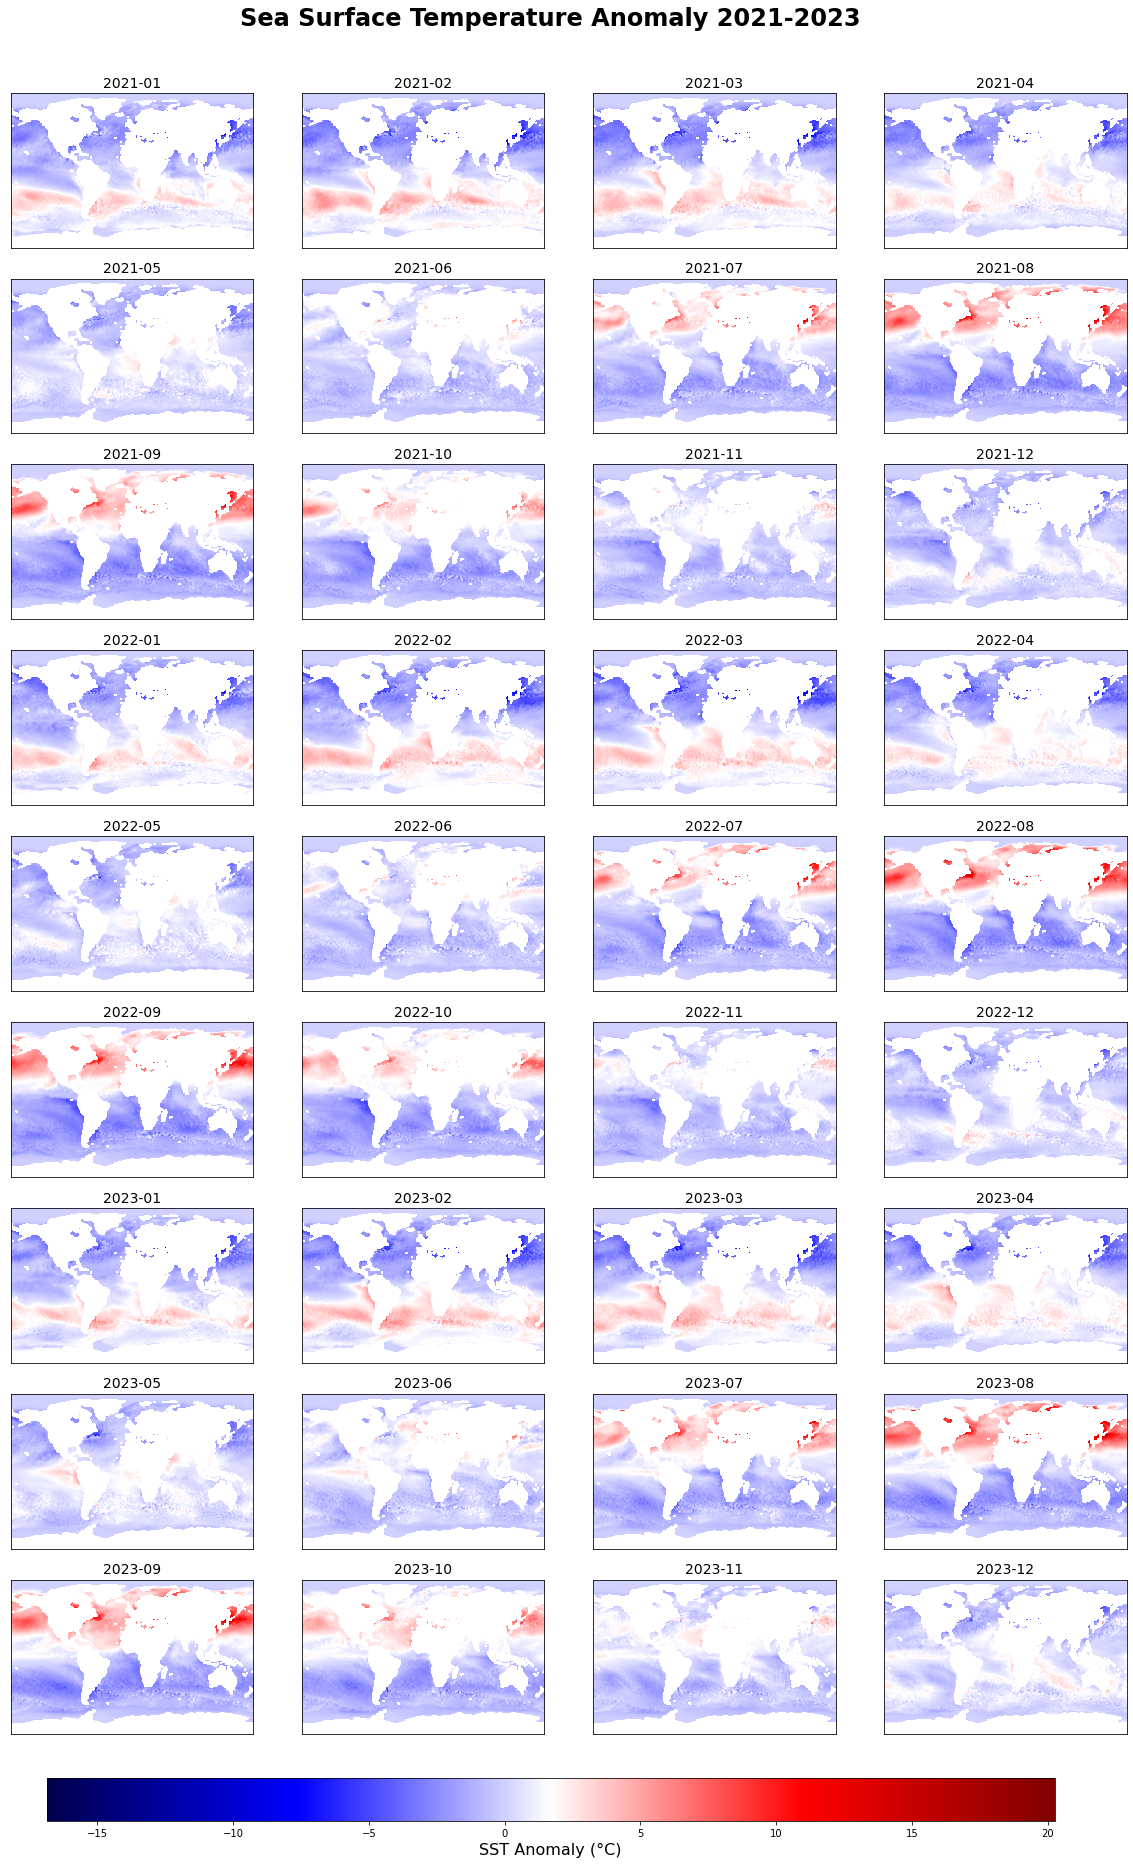

In [11]:
# **Filter data from 2021-01-01 to 2022-12-01**
anomalies = anomalies.sel(date=slice("2021-01-01", "2023-12-01"))

# **Fix 1: Compute Global Min/Max Anomaly for Consistent Color Scale**
vmin, vmax = anomalies.to_array().min().item(), anomalies.to_array().max().item()

# **Fix 2: Adjust Longitude for Africa-Centered View**
anomalies = anomalies.assign_coords(longitude=(((anomalies.longitude + 180) % 360) - 180)).sortby("longitude")

# **Fix 3: Explicitly Flip Latitude if Needed**
if anomalies.latitude[0] > anomalies.latitude[-1]:  # Check if latitudes are descending
    anomalies = anomalies.sortby("latitude", ascending=True)  # Reorder to ascending

# **Create a Single Figure with a Grid Layout**
num_months = len(anomalies.date)  # Count number of months
ncols = 4  # Number of columns
nrows = -(-num_months // ncols)  # Compute rows (ceil division)

# **Create a Single Figure with a Grid Layout**
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 30), constrained_layout=True)
fig.subplots_adjust(bottom=0.12)  # Adjust space for colorbar

# **Add Figure Title**
fig.suptitle("Sea Surface Temperature Anomaly 2021-2023", fontsize=24, fontweight='bold', y=0.92)
# Flatten axes for flexible plotting
axes = axes.flatten()

# Get all dates
dates = anomalies.date.values

# Loop through each month and plot in grid
for ax, date in zip(axes.flat, dates):
    sst_anomaly = anomalies.sel(date=date).to_array().squeeze()

    # Flip latitude if needed
    if anomalies.latitude[0] > anomalies.latitude[-1]:
        sst_anomaly = sst_anomaly[::-1]

    # Plot SST anomaly
    im = ax.imshow(
        sst_anomaly[::-1], cmap='seismic', vmin=vmin, vmax=vmax, aspect='auto',
        extent=[anomalies.longitude.min(), anomalies.longitude.max(),
                anomalies.latitude.min(), anomalies.latitude.max()]
    )

    # Add title to each subplot
    ax.set_title(f"{pd.to_datetime(date).strftime('%Y-%m')}", fontsize=14)
    ax.set_xticks([])
    ax.set_yticks([])

# Add a common colorbar for all subplots
cbar_ax = fig.add_axes([0.15, 0.08, 0.7, 0.02])  # Positioning the colorbar
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label("SST Anomaly (°C)", fontsize=16)

# Save the combined figure
plt.savefig("SSTAnomalies_2021-2023.png", dpi=600)

# Show the figure
plt.show()

**Seasonal SST anomalies**

In [3]:
import xarray as xr
import pandas as pd
import numpy as np

# Load dataset
ds = xr.open_dataset("sst.nc", engine="netcdf4")  # Load NetCDF file

# Convert 'date' from integer to datetime format
ds = ds.assign_coords(date=pd.to_datetime(ds['date'].data.astype(str), format='%Y%m%d'))

# Convert dataset to DataFrame
df = ds['sst'].to_dataframe().reset_index()

# Extract year and month
df = df.drop('expver', axis=1)
df = df.drop('number', axis=1)
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

# **FAST NumPy Vectorized Method for Assigning Seasons**
seasons = np.array(["Winter", "Spring", "Summer", "Autumn"])

# Define conditions for season assignment
winter = df['month'].isin([12, 1, 2])
spring = df['month'].isin([3, 4, 5])
summer = df['month'].isin([6, 7, 8])
autumn = df['month'].isin([9, 10, 11])

# Assign seasons using np.select (much faster than apply)
df['season'] = np.select([winter, spring, summer, autumn], seasons)

# Assign season_year (December belongs to next year’s winter)
df['season_year'] = df['year']
df.loc[df['month'] == 12, 'season_year'] += 1  # Shift December to next year's winter

# **STEP 1: Compute Actual Seasonal SST (For Each Year)**
seasonal_sst_df = df.groupby(['latitude', 'longitude', 'season_year', 'season'])['sst'].mean().reset_index()

# **STEP 2: Compute Seasonal Climatology (Long-Term Average Over All Years)**
seasonal_climatology_df = seasonal_sst_df.groupby(['latitude', 'longitude', 'season'])['sst'].mean().reset_index()
seasonal_climatology_df.rename(columns={'sst': 'sst_climatology'}, inplace=True)

# **STEP 3: Merge Actual SST With Climatology**
mergedf = pd.merge(seasonal_sst_df, seasonal_climatology_df, on=['latitude', 'longitude', 'season'], how="left")
# **STEP 4: Compute Seasonal Anomalies**
mergedf['sst_anomaly'] = mergedf['sst'] - mergedf['sst_climatology']

mergedf['date'] = (
    mergedf['season'].astype(str) 
    + ' ' 
    + mergedf['season_year'].astype(str)
)
mergedf

,date,latitude,longitude,sst,year,month
0,1983-01-01,90.0,0.00,271.460205,1983,1
1,1983-01-01,90.0,0.25,271.460205,1983,1
2,1983-01-01,90.0,0.50,271.460205,1983,1
3,1983-01-01,90.0,0.75,271.460205,1983,1
4,1983-01-01,90.0,1.00,271.460205,1983,1
...,...,...,...,...,...,...
510814075,2023-12-01,-90.0,358.75,NaN,2023,12
510814076,2023-12-01,-90.0,359.00,NaN,2023,12
510814077,2023-12-01,-90.0,359.25,NaN,2023,12
510814078,2023-12-01,-90.0,359.50,NaN,2023,12


In [9]:
# Convert back to xarray
anomalies = mergedf.set_index(['date', 'latitude', 'longitude'])['sst_anomaly'].to_xarray()
anomalies

<xarray.DataArray 'sst_anomaly' (date: 165, latitude: 721, longitude: 1440)>
array([[[           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        ...,
        [-9.1552734e-05, -9.1552734e-05, -9.1552734e-05, ...,
         -9.1552734e-05, -9.1552734e-05, -9.1552734e-05],
        [-9.1552734e-05, -3.6621094e-04, -3.9672852e-04, ...,
         -9.1552734e-05, -9.1552734e-05, -9.1552734e-05],
        [-9.1552734e-05, -9.1552734e-05, -9.1552734e-05, ...,
         -9.1552734e-05, -9.1552734e-05, -9.1552734e-05]],

       [[           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
...
        [ 2.1362305e-04,  2.1362305e-04,  2.1362305e-04, ...,
          2.4414062e-04,  2.1362305e-04,  2.1362305e-04],
        [ 2.1362305e-04, -6.1035156e-05,  2.4414062e-04, ...,
          2.1362305e-04,  2.1362305e-04,  2.1362305e-04],
        [ 2.1362305e-04,  2.1362305e-04,  2.1362305e-04, ...,
          2.1362305e-04,  2.1362305e-04,  2.1362305e-04]],

       [[           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        ...,
        [ 1.2207031e-04,  1.2207031e-04,  1.2207031e-04, ...,
          1.5258789e-04,  1.2207031e-04,  1.2207031e-04],
        [ 1.2207031e-04,  1.8310547e-04,  1.5258789e-04, ...,
          1.2207031e-04,  1.2207031e-04,  1.2207031e-04],
        [ 1.2207031e-04,  1.2207031e-04,  1.2207031e-04, ...,
          1.2207031e-04,  1.2207031e-04,  1.2207031e-04]]], dtype=float32)
Coordinates:
  * date       (date) object 'Autumn 1983' 'Autumn 1984' ... 'Winter 2024'
  * latitude   (latitude) float64 -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * longitude  (longitude) float64 0.0 0.25 0.5 0.75 ... 359.0 359.2 359.5 359.8

In [10]:
# Save SST anomalies dataset as a NetCDF file
anomalies.to_netcdf("sst_seasonal_anomalies.nc")

**Plotting sst seasonal anomalies**

In [5]:
anomalies= xr.open_dataset('data/sst_seasonal_anomalies.nc', engine='netcdf4')
anomalies

<xarray.Dataset>
Dimensions:      (date: 165, latitude: 721, longitude: 1440)
Coordinates:
  * date         (date) object 'Autumn 1983' 'Autumn 1984' ... 'Winter 2024'
  * latitude     (latitude) float64 -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * longitude    (longitude) float64 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
Data variables:
    sst_anomaly  (date, latitude, longitude) float32 ...

<ipython-input-7-e570ebacc46e>:25: UserWarning: This figure was using constrained_layout==True, but that is incompatible with subplots_adjust and or tight_layout: setting constrained_layout==False. 
  fig.subplots_adjust(bottom=0.12)  # Adjust space for colorbar


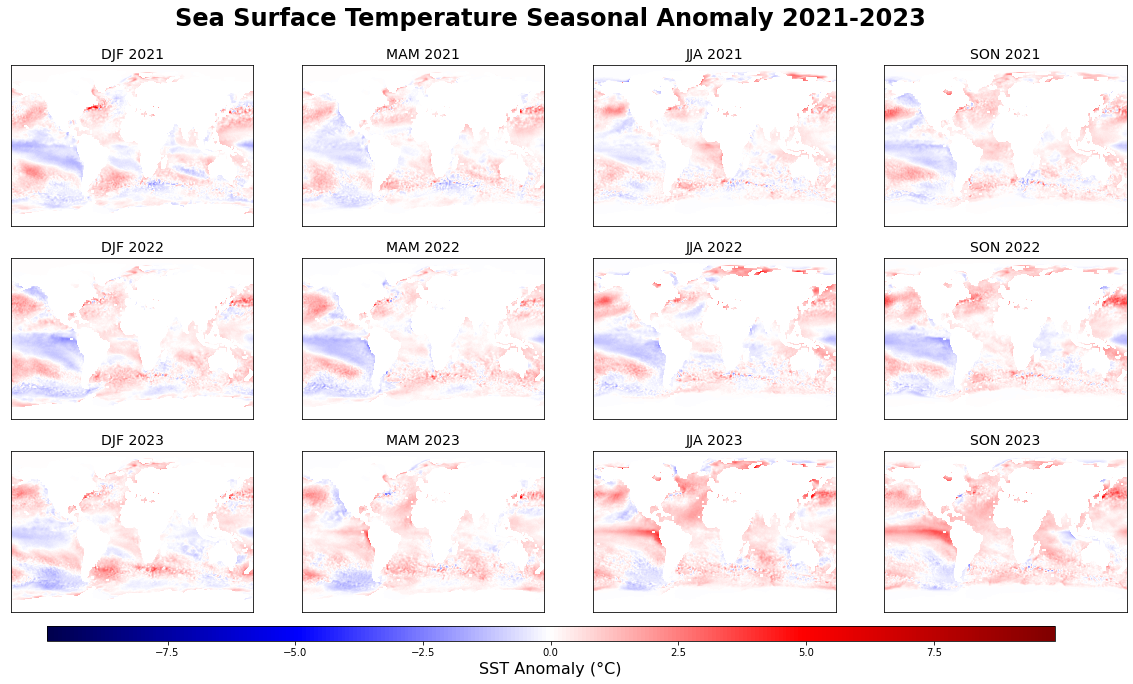

In [7]:
# **Filter data from 2021-01-01 to 2022-12-01**
seasons = ['Winter 2021', 'Spring 2021', 'Summer 2021', 'Autumn 2021', 
           'Winter 2022', 'Spring 2022', 'Summer 2022', 'Autumn 2022',
           'Winter 2023', 'Spring 2023', 'Summer 2023', 'Autumn 2023',]
anomalies = anomalies.sel(date=seasons)

# **Fix 1: Compute Global Min/Max Anomaly for Consistent Color Scale**
vmin, vmax = anomalies.to_array().min().item(), anomalies.to_array().max().item()
absmax = max(vmax, abs(vmin))

# **Fix 2: Adjust Longitude for Africa-Centered View**
anomalies = anomalies.assign_coords(longitude=(((anomalies.longitude + 180) % 360) - 180)).sortby("longitude")

# **Fix 3: Explicitly Flip Latitude if Needed**
if anomalies.latitude[0] > anomalies.latitude[-1]:  # Check if latitudes are descending
    anomalies = anomalies.sortby("latitude", ascending=True)  # Reorder to ascending

# **Create a Single Figure with a Grid Layout**
num_months = len(anomalies.date)  # Count number of months
ncols = 4  # Number of columns
nrows = -(-num_months // ncols)  # Compute rows (ceil division)

# **Create a Single Figure with a Grid Layout**
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 10), constrained_layout=True)
fig.subplots_adjust(bottom=0.12)  # Adjust space for colorbar

# **Add Figure Title**
fig.suptitle("Sea Surface Temperature Seasonal Anomaly 2021-2023", fontsize=24, fontweight='bold', y=0.96)
# Flatten axes for flexible plotting
axes = axes.flatten()

# Get all dates
dates = anomalies.date.values

# Mapping full season names to short codes
season_map = {
    'Winter': 'DJF',
    'Spring': 'MAM',
    'Summer': 'JJA',
    'Autumn': 'SON'
}
season_labels = [season_map[s.split()[0]] + ' ' + s.split()[1] for s in seasons]

# Loop through each month and plot in grid
for ax, date, label in zip(axes.flat, dates, season_labels):
    sst_anomaly = anomalies.sel(date=date).to_array().squeeze()

    # Flip latitude if needed
    if anomalies.latitude[0] > anomalies.latitude[-1]:
        sst_anomaly = sst_anomaly[::-1]

    # Plot SST anomaly
    im = ax.imshow(
        sst_anomaly[::-1], cmap='seismic', vmin=absmax*(-1), vmax=absmax, aspect='auto',
        extent=[anomalies.longitude.min(), anomalies.longitude.max(),
                anomalies.latitude.min(), anomalies.latitude.max()]
    )

    # Add title to each subplot
    ax.set_title(label, fontsize=14)
    ax.set_xticks([])
    ax.set_yticks([])

# Add a common colorbar for all subplots
cbar_ax = fig.add_axes([0.15, 0.08, 0.7, 0.02])  # Positioning the colorbar
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label("SST Anomaly (°C)", fontsize=16)

# Save the combined figure
plt.savefig("SSTSeasonalAnomalies_2021-2023.png", dpi=600)

# Show the figure
plt.show()

**Annual SST anomalies**

In [ ]:
import xarray as xr
import pandas as pd
import numpy as np

# Load dataset
ds = xr.open_dataset("sst.nc", engine="netcdf4")  # Load NetCDF file

# Convert 'date' from integer to datetime format
ds = ds.assign_coords(date=pd.to_datetime(ds['date'].data.astype(str), format='%Y%m%d'))

# Convert dataset to DataFrame
df = ds['sst'].to_dataframe().reset_index()

# Extract year and month
df = df.drop('expver', axis=1)
df = df.drop('number', axis=1)
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

# **FAST NumPy Vectorized Method for Assigning Seasons**
seasons = np.array(["Winter", "Spring", "Summer", "Autumn"])

# Define conditions for season assignment
winter = df['month'].isin([12, 1, 2])
spring = df['month'].isin([3, 4, 5])
summer = df['month'].isin([6, 7, 8])
autumn = df['month'].isin([9, 10, 11])

# Assign seasons using np.select (much faster than apply)
df['season'] = np.select([winter, spring, summer, autumn], seasons)

# Assign season_year (December belongs to next year’s winter)
df['season_year'] = df['year']
df.loc[df['month'] == 12, 'season_year'] += 1  # Shift December to next year's winter

# **STEP 1: Compute Actual Seasonal SST (For Each Year)**
seasonal_sst_df = df.groupby(['latitude', 'longitude', 'season_year', 'season'])['sst'].mean().reset_index()

# **STEP 2: Compute Seasonal Climatology (Long-Term Average Over All Years)**
seasonal_climatology_df = seasonal_sst_df.groupby(['latitude', 'longitude', 'season'])['sst'].mean().reset_index()
seasonal_climatology_df.rename(columns={'sst': 'sst_climatology'}, inplace=True)

# **STEP 3: Merge Actual SST With Climatology**
mergedf = pd.merge(seasonal_sst_df, seasonal_climatology_df, on=['latitude', 'longitude', 'season'], how="left")
# **STEP 4: Compute Seasonal Anomalies**
mergedf['sst_anomaly'] = mergedf['sst'] - mergedf['sst_climatology']

mergedf['date'] = (
    mergedf['season'].astype(str) 
    + ' ' 
    + mergedf['season_year'].astype(str)
)
mergedf

In [2]:
# Load dataset (Uncomment if loading from file)
#xarry bach n7ol les fichier
# Load dataset
ds = xr.open_dataset("sst.nc", engine="netcdf4")  # Load NetCDF file

# Convert 'date' from integer to datetime format
ds = ds.assign_coords(date=pd.to_datetime(ds['date'].data.astype(str), format='%Y%m%d'))

# Convert dataset to DataFrame
df = ds['sst'].to_dataframe().reset_index()

# Extract month from date
df['year'] = df['date'].dt.year

# **STEP 1: Compute Actual Seasonal SST (For Each Year)**
annual_sst_df = df.groupby(['latitude', 'longitude', 'year'])['sst'].mean().reset_index()

# **STEP 2: Compute Seasonal Climatology (Long-Term Average Over All Years)**
annual_climatology_df = annual_sst_df.groupby(['latitude', 'longitude'])['sst'].mean().reset_index()
annual_climatology_df.rename(columns={'sst': 'sst_climatology'}, inplace=True)

# **STEP 3: Merge Actual SST With Climatology**
mergedf = pd.merge(annual_sst_df, annual_climatology_df, on=['latitude', 'longitude'], how="left")
# **STEP 4: Compute Seasonal Anomalies**
mergedf['sst_anomaly'] = mergedf['sst'] - mergedf['sst_climatology']
mergedf
#Convert back to xarray
#anomalies = df.set_index(['date', 'latitude', 'longitude'])['sst_anomaly'].to_xarray()

,latitude,longitude,year,sst,sst_climatology,sst_anomaly
0,-90.0,0.00,1983,NaN,NaN,NaN
1,-90.0,0.00,1984,NaN,NaN,NaN
2,-90.0,0.00,1985,NaN,NaN,NaN
3,-90.0,0.00,1986,NaN,NaN,NaN
4,-90.0,0.00,1987,NaN,NaN,NaN
...,...,...,...,...,...,...
42567835,90.0,359.75,2019,271.460052,271.460083,-0.000031
42567836,90.0,359.75,2020,271.459869,271.460083,-0.000214
42567837,90.0,359.75,2021,271.460236,271.460083,0.000153
42567838,90.0,359.75,2022,271.460022,271.460083,-0.000061


In [7]:
# Convert back to xarray
anomalies = mergedf.set_index(['year', 'latitude', 'longitude'])['sst_anomaly'].to_xarray()
anomalies

<xarray.DataArray 'sst_anomaly' (year: 41, latitude: 721, longitude: 1440)>
array([[[           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        ...,
        [-6.1035156e-05, -6.1035156e-05, -6.1035156e-05, ...,
         -6.1035156e-05, -6.1035156e-05, -6.1035156e-05],
        [-6.1035156e-05, -1.5258789e-04, -1.8310547e-04, ...,
         -6.1035156e-05, -6.1035156e-05, -6.1035156e-05],
        [-6.1035156e-05, -6.1035156e-05, -6.1035156e-05, ...,
         -6.1035156e-05, -6.1035156e-05, -6.1035156e-05]],

       [[           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
...
        [-6.1035156e-05, -6.1035156e-05, -6.1035156e-05, ...,
         -6.1035156e-05, -6.1035156e-05, -6.1035156e-05],
        [-6.1035156e-05,  0.0000000e+00, -3.0517578e-05, ...,
         -6.1035156e-05, -6.1035156e-05, -6.1035156e-05],
        [-6.1035156e-05, -6.1035156e-05, -6.1035156e-05, ...,
         -6.1035156e-05, -6.1035156e-05, -6.1035156e-05]],

       [[           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        ...,
        [-9.1552734e-05, -9.1552734e-05, -9.1552734e-05, ...,
         -1.5258789e-04, -9.1552734e-05, -9.1552734e-05],
        [-9.1552734e-05, -9.1552734e-05, -6.1035156e-05, ...,
         -9.1552734e-05, -9.1552734e-05, -9.1552734e-05],
        [-9.1552734e-05, -9.1552734e-05, -9.1552734e-05, ...,
         -9.1552734e-05, -9.1552734e-05, -9.1552734e-05]]], dtype=float32)
Coordinates:
  * year       (year) int32 1983 1984 1985 1986 1987 ... 2020 2021 2022 2023
  * latitude   (latitude) float64 -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * longitude  (longitude) float64 0.0 0.25 0.5 0.75 ... 359.0 359.2 359.5 359.8

In [4]:
# Save SST anomalies dataset as a NetCDF file
anomalies.to_netcdf("sst_annual_anomalies.nc")

<ipython-input-17-81c54f66ab24>:21: UserWarning: This figure was using constrained_layout==True, but that is incompatible with subplots_adjust and or tight_layout: setting constrained_layout==False. 
  fig.subplots_adjust(bottom=0.12)  # Adjust space for colorbar


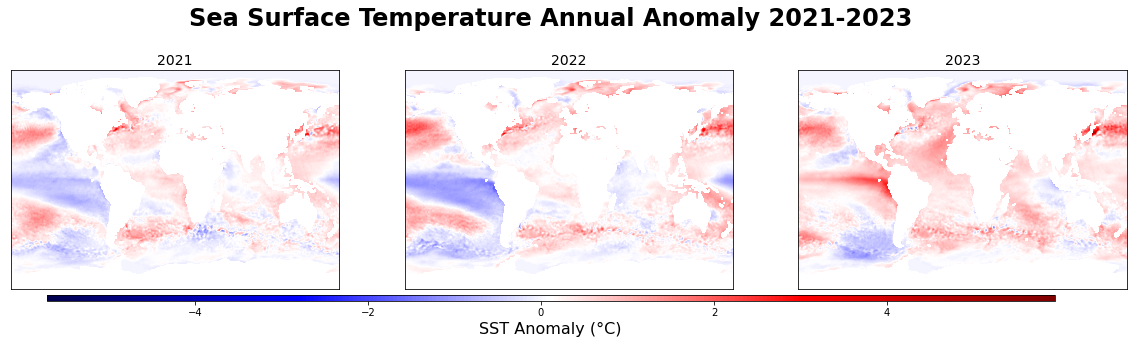

In [17]:
# **Filter data from 2021-01-01 to 2022-12-01**
anomalies = anomalies.sel(year=slice("2021", "2023"))

# **Fix 1: Compute Global Min/Max Anomaly for Consistent Color Scale**
vmin, vmax = anomalies.min().item(), anomalies.max().item()

# **Fix 2: Adjust Longitude for Africa-Centered View**
anomalies = anomalies.assign_coords(longitude=(((anomalies.longitude + 180) % 360) - 180)).sortby("longitude")

# **Fix 3: Explicitly Flip Latitude if Needed**
if anomalies.latitude[0] > anomalies.latitude[-1]:  # Check if latitudes are descending
    anomalies = anomalies.sortby("latitude", ascending=True)  # Reorder to ascending

# **Create a Single Figure with a Grid Layout**
num_months = len(anomalies.year)  # Count number of months
ncols = 3  # Number of columns
nrows = -(-num_months // ncols)  # Compute rows (ceil division)

# **Create a Single Figure with a Grid Layout**
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 4), constrained_layout=True)
fig.subplots_adjust(bottom=0.12)  # Adjust space for colorbar

# **Add Figure Title**
fig.suptitle("Sea Surface Temperature Annual Anomaly 2021-2023", fontsize=24, fontweight='bold', y=1.1)
# Flatten axes for flexible plotting
axes = axes.flatten()

# Get all dates
years = anomalies.year.values

# Loop through each month and plot in grid
for ax, year in zip(axes.flat, years):
    sst_anomaly = anomalies.sel(year=year).squeeze()

    # Flip latitude if needed
    if anomalies.latitude[0] > anomalies.latitude[-1]:
        sst_anomaly = sst_anomaly[::-1]

    # Plot SST anomaly
    im = ax.imshow(
        sst_anomaly[::-1], cmap='seismic', vmin=vmin, vmax=vmax, aspect='auto',
        extent=[anomalies.longitude.min(), anomalies.longitude.max(),
                anomalies.latitude.min(), anomalies.latitude.max()]
    )

    # Add title to each subplot
    ax.set_title(f"{year}", fontsize=14)
    ax.set_xticks([])
    ax.set_yticks([])

# Add a common colorbar for all subplots
cbar_ax = fig.add_axes([0.15, 0.08, 0.7, 0.02])  # Positioning the colorbar
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label("SST Anomaly (°C)", fontsize=16)

# Save the combined figure
plt.savefig("SSTAnnualAnomalies_2021-2023.png", dpi=600)

# Show the figure
plt.show()

**Interactive map**

In [20]:
!pip install pillow

Defaulting to user installation because normal site-packages is not writeable


In [17]:
!sudo apt install ffmpeg


We trust you have received the usual lecture from the local System
Administrator. It usually boils down to these three things:

    #1) Respect the privacy of others.
    #2) Think before you type.
    #3) With great power comes great responsibility.

[sudo] password for anas.oubaha: 


In [18]:
print(anomalies.latitude.values[:10])  # Check first 10 values

[-90.   -89.75 -89.5  -89.25 -89.   -88.75 -88.5  -88.25 -88.   -87.75]


TypeError: float() argument must be a string or a number, not 'method'

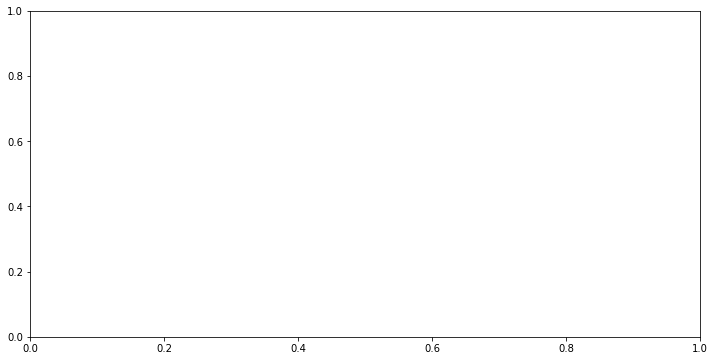

In [22]:
import matplotlib.animation as animation
# Get all available dates
dates = anomalies.date.values

# **Fix 1: Compute global min/max anomaly for color consistency**
vmin, vmax = anomalies.min().values, anomalies.max().values  # Set fixed scale

# **Fix 2: Adjust longitude for Africa-centered view**
anomalies = anomalies.assign_coords(longitude=(((anomalies.longitude + 180) % 360) - 180)).sortby("longitude")

# Set up the figure
fig, ax = plt.subplots(figsize=(12, 6))

# Initialize the plot with fixed vmin, vmax
im = ax.imshow(
    np.zeros((len(anomalies.latitude), len(anomalies.longitude))), 
    aspect='auto', cmap='coolwarm', vmin=vmin, vmax=vmax,
    extent=[anomalies.longitude.min(), anomalies.longitude.max(),
            anomalies.latitude.min(), anomalies.latitude.max()]
)

# Flip latitude if needed
anomalies = anomalies.sortby("latitude")

# Add colorbar
cbar = plt.colorbar(im, ax=ax, orientation="horizontal", pad=0.05)
cbar.set_label("SST Anomaly (°C)")

# Title
title = ax.set_title("")

# Function to update each frame
def update(frame):
    date = dates[frame]
    sst_anomaly = anomalies.sel(date=date).to_array().squeeze()

    # Flip latitude if inverted
    if anomalies.latitude[0] > anomalies.latitude[-1]:
        sst_anomaly = sst_anomaly[::-1]

    im.set_array(sst_anomaly)  # Update data without changing color scale
    title.set_text(f"Sea Surface Temperature Anomaly ({pd.to_datetime(date).strftime('%Y-%m')})")
    return [im, title]

# Create animation
ani = animation.FuncAnimation(fig, update, frames=len(dates), interval=50, blit=False)

# Save as GIF (since ffmpeg is unavailable)
ani.save("sst_anomaly_animation.gif", writer="pillow", fps=15)

# Show the animation (optional)
plt.show()